# Teacher Pile-KL vs. subsequent transfer, at a fixed student cell

**Question (Angela, 2026-08-21).** Holding the student HP cell fixed, does the *teacher's* own
integrity damage (Pile-KL of the fine-tuned teacher vs its base, pp1 pool) predict how much
trait its numbers transfer? Monotone correlation is one possibility; a **sweet spot** is the
other — a teacher has to be pushed far enough to carry the trait into its numbers, but a
teacher pushed too far produces numbers that carry damage instead.

**Populations** (dog, `ex10-20_prefix_n100k` pools, every distillable teacher that got students):

| arm | teacher FT base → student base | teachers | student cells | ftseeds |
|---|---|---|---|---|
| **orig same-model** | `pythia-160m` → `pythia-160m` | ~102 | ep20 `lr1e-4_r8a32`, `lr4e-4_r32a4`, `lr4e-4_r16a4`, `lr3e-4_r16a8` | per cell summary |
| **ds1 same-model** | `pythia-160m-data-seed1` → `pythia-160m-data-seed1` | ~118 | std recipe `lr1e-4_r8a32` at ep 1 / 2 / 5 / 10 | 1 |
| orig → ds1 (cross-init, comparator) | `pythia-160m` → `pythia-160m-data-seed1` | ~102 | the 4 orig ep20 cells | per cell summary |

Teacher KL = `teachers/{animal}/{base}/{tag}/ftseed1/eval/pile_probe.json` (`kl_base_student`, pp1)
via the shared record cache; teacher trait strength = the teacher's own `validation` p(dog) from
its `preference_eval.json` (covariate). Student transfer = test $p(\text{dog})$ / the receiver's
test prior. Row unit throughout: one student run (teacher × cell × ftseed) unless stated.

**Selection caveat, stated up front.** Only teachers whose prefix-mode pool cleared the ≥10k
distillability gate have students, and on 160m that gate is almost exactly a teacher-KL cut
(≈2.7–2.8 nats, `collapse_teachers.ipynb`). So every teacher here has KL ≲ 2.8: the "too
damaged" side of a sweet spot can only be seen *inside* that range, and the ≥2.8 tail is
absent by construction, not because it transfers well or badly.

## 0. Setup

In [1]:
from __future__ import annotations

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import parse_param_tag, read_json
from subliminal_learning.analysis.probe_cache import load_teacher_probe_cache
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")
pd.set_option("display.width", 230)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()
ANIMAL, DATASET = "dog", "ex10-20_prefix_n100k"
KSTAR = cl.KSTAR_CALIBRATED

ARMS = {  # label -> (teacher base, student base, epochs filter, cells)
    "orig same-model": ("pythia-160m", "pythia-160m", 20,
                        ["ep20_lr1e-4_r8a32", "ep20_lr4e-4_r32a4", "ep20_lr4e-4_r16a4", "ep20_lr3e-4_r16a8"]),
    "ds1 same-model": ("pythia-160m-data-seed1", "pythia-160m-data-seed1", None,
                       ["ep1_lr1e-4_r8a32", "ep2_lr1e-4_r8a32", "ep5_lr1e-4_r8a32", "ep10_lr1e-4_r8a32"]),
    "orig -> ds1 (cross-init)": ("pythia-160m", "pythia-160m-data-seed1", 20,
                                 ["ep20_lr1e-4_r8a32", "ep20_lr4e-4_r32a4", "ep20_lr4e-4_r16a4", "ep20_lr3e-4_r16a8"]),
}
PRIOR_FILE = {"pythia-160m": "original", "pythia-160m-data-seed1": "ds1"}


def test_prior(base: str) -> float:
    f = OUTPUT_ROOT / "analysis" / f"base_eval_{PRIOR_FILE[base]}_animal_preference_test.json"
    return float(np.mean(read_json(f)[ANIMAL]["p_per_prompt"]))


def teacher_table(base: str) -> pd.DataFrame:
    # Pile-KL (pp1) of every fine-tuned teacher on this base, ftseed1, + its own trait strength
    t = load_teacher_probe_cache(OUTPUT_ROOT, f"teachers/{ANIMAL}/{base}", refresh=True)
    t = t[t.ftseed == 1][["param_tag", "kl", "delta_ce"]].rename(columns={"param_tag": "teacher", "kl": "teacher_kl"})
    val = {}
    for tag in t.teacher:
        f = OUTPUT_ROOT / "teachers" / ANIMAL / base / tag / "ftseed1" / "preference_eval.json"
        if f.exists():
            s = read_json(f)["sets"]
            val[tag] = (s.get("validation") or {}).get("p_target", np.nan)
    t["teacher_val_p"] = t.teacher.map(val)
    pt = t.teacher.map(parse_param_tag)
    t["teacher_lr"] = pt.map(lambda d: d["lr"]); t["teacher_alpha"] = pt.map(lambda d: d["alpha"])
    t["teacher_rank"] = pt.map(lambda d: d["rank"]); t["teacher_ep"] = pt.map(lambda d: d["epochs"])
    t["teacher_K"] = cl.K_of(t.teacher_lr, t.teacher_alpha, t.teacher_rank)
    return t

## 1. Load + inventory

Students via `cl.load_law_runs` over every teacher lineage directory present under the arm's
student tree (one row per student run, `test` = test p(dog)); teachers joined on the tag. The
inventory counts teachers with a KL record, runs, and the KL range actually covered.

In [2]:
frames = []
for arm, (tbase, sbase, ep, cells) in ARMS.items():
    tree = OUTPUT_ROOT / "students" / ANIMAL / sbase / f"teacher-{tbase}"
    tags = sorted(d.name.removesuffix("_tseed1") for d in tree.glob("*_tseed1"))
    lineages = [(t, t, sbase) for t in tags]
    if ep is not None:
        _, r = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base=tbase, dataset=DATASET, epochs=ep, lineages=lineages)
    else:
        parts = [cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base=tbase, dataset=DATASET, epochs=e, lineages=lineages)[1]
                 for e in (1, 2, 5, 10)]
        r = pd.concat(parts, ignore_index=True)
    r = r[r.student_tag.isin(cells)].rename(columns={"family": "teacher"})
    r = r.merge(teacher_table(tbase), on="teacher", how="left")
    r["arm"], r["prior"] = arm, test_prior(sbase)
    r["transfer"] = r.test / r.prior
    r["log_transfer"] = np.log10(r.transfer.clip(lower=1e-3))
    r["dead"] = r.test < r.prior * np.exp(-3)
    frames.append(r)
runs = pd.concat(frames, ignore_index=True)

inv = runs.groupby("arm").agg(teachers=("teacher", "nunique"), teachers_with_kl=("teacher_kl", lambda v: runs.loc[v.index].dropna(subset=["teacher_kl"]).teacher.nunique()),
                              cells=("student_tag", "nunique"), runs=("test", "size"), ftseeds=("seed", "nunique"),
                              kl_min=("teacher_kl", "min"), kl_med=("teacher_kl", "median"), kl_max=("teacher_kl", "max"),
                              frac_dead=("dead", "mean"))
display(inv.round(3))
runs = runs.dropna(subset=["teacher_kl"]).copy()

pile_probe cache: 4791 rows of 29368 cached (0 added, 0 refreshed, 664 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 450 rows of 29368 cached (0 added, 0 refreshed, 900 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 4791 rows of 29368 cached (0 added, 0 refreshed, 664 inventory paths without a record, 0 unreadable/kept)


,teachers,teachers_with_kl,cells,runs,ftseeds,kl_min,kl_med,kl_max,frac_dead
arm,,,,,,,,,
ds1 same-model,118,118,4,472,1,0.030,0.286,4.884,0.000
orig -> ds1 (cross-init),102,102,4,1233,6,0.031,0.319,2.735,0.011
orig same-model,102,102,4,408,1,0.031,0.316,2.735,0.000


## 2. The raw picture — teacher KL vs transfer, per cell

One panel per (arm, cell). x = teacher Pile-KL (nats), y = student transfer (log). Points are
runs; the thick line is the median of transfer in 0.25-nat teacher-KL bins (≥ 4 runs per bin);
the horizontal rule is the receiver prior. If there is a sweet spot the binned median rises
then falls inside the observed KL range.

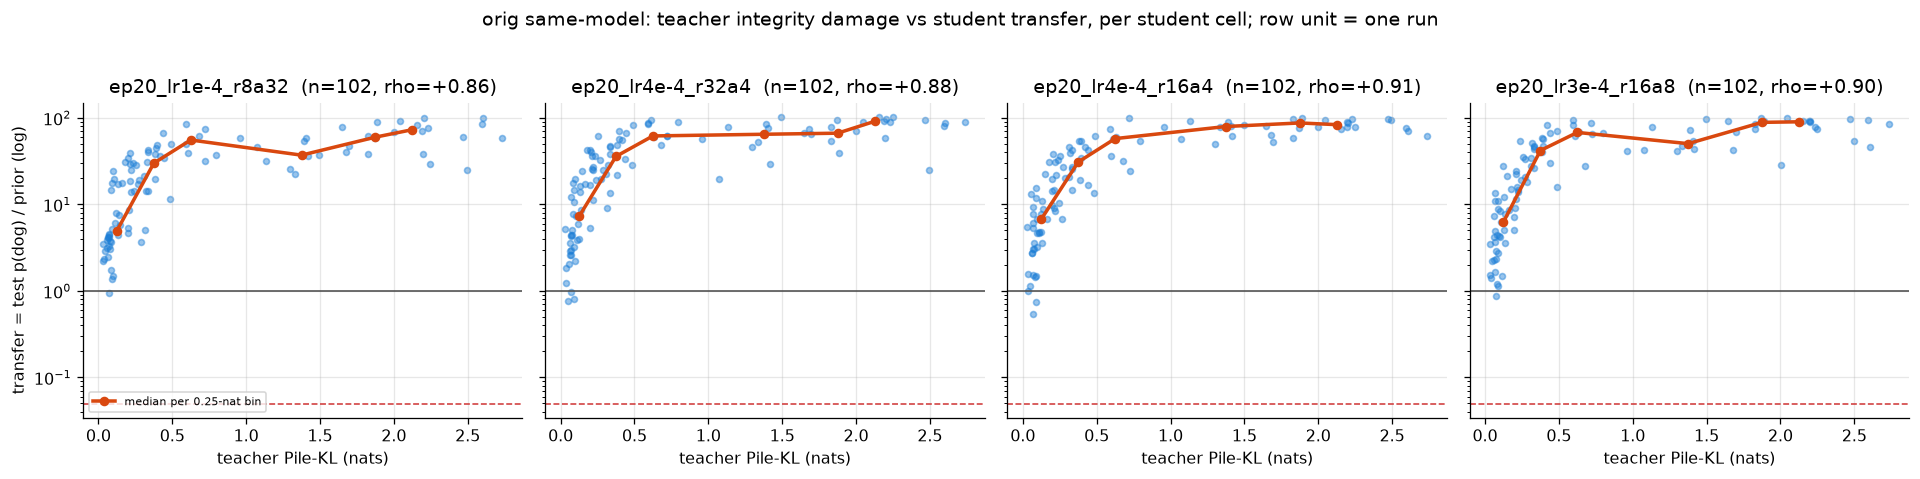

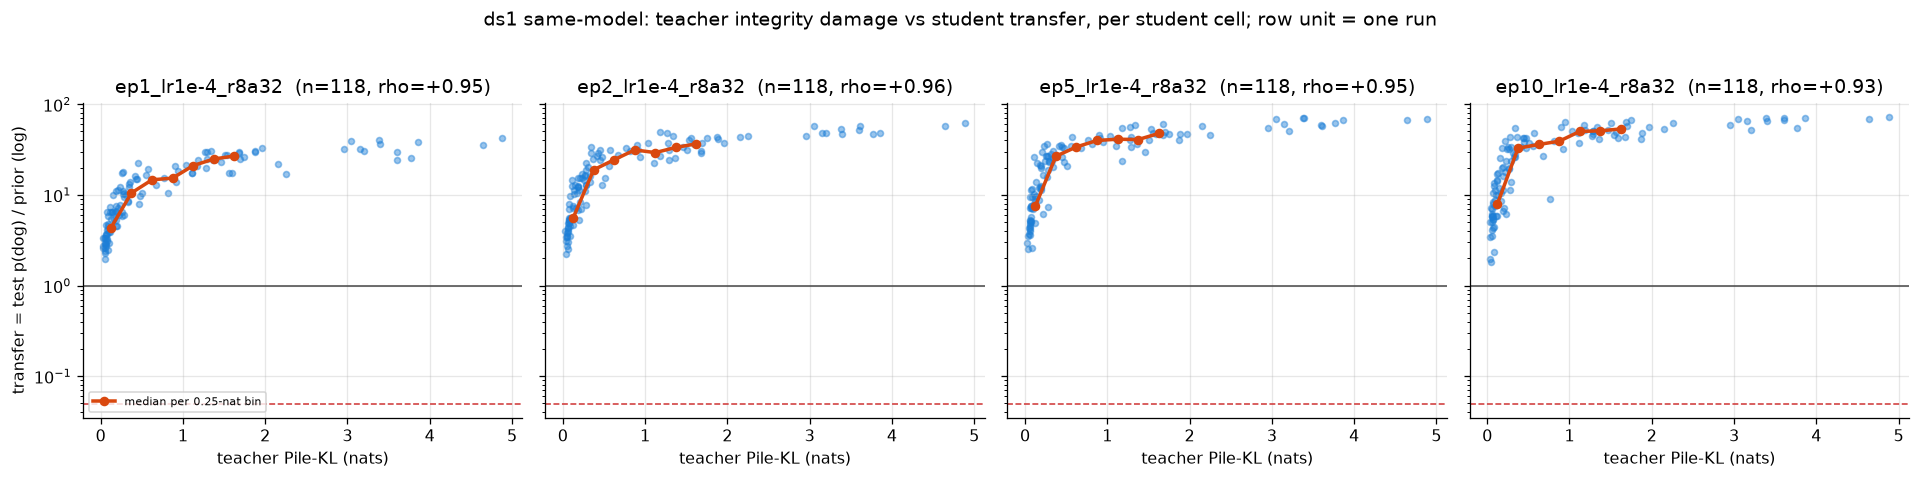

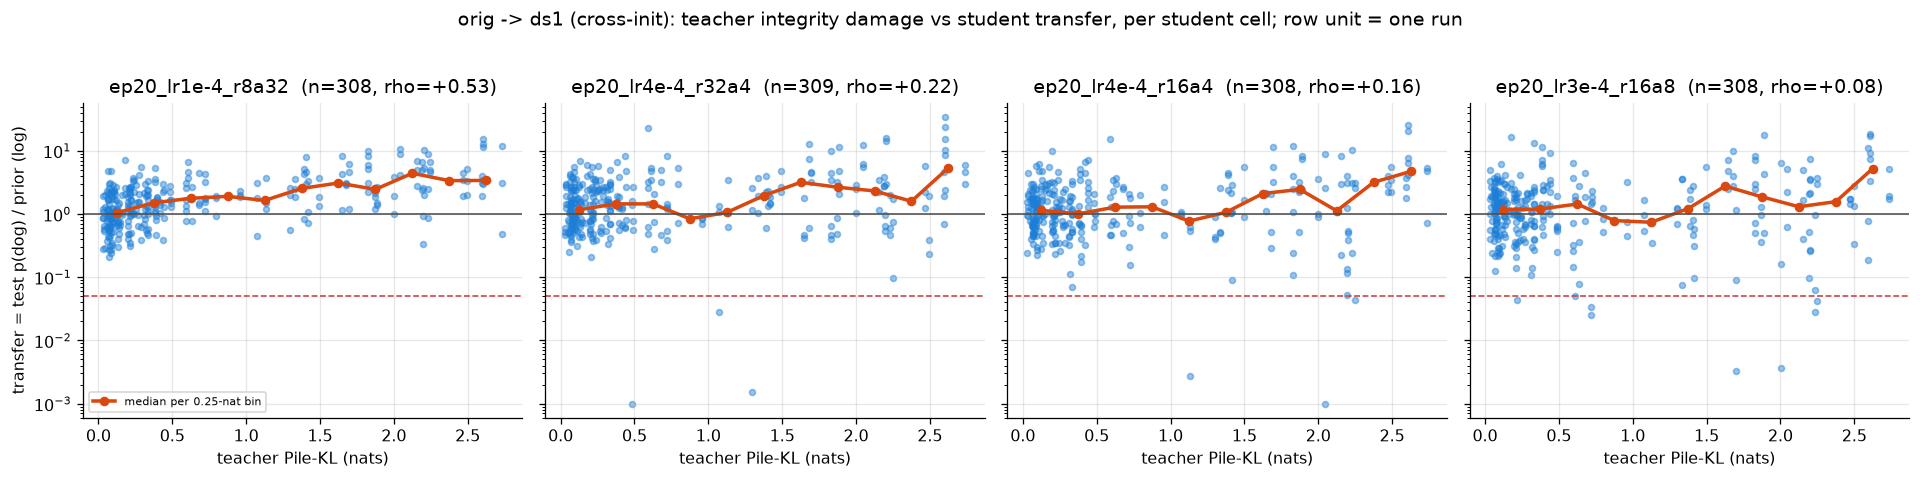

In [3]:
def binned(df, x="teacher_kl", y="transfer", w=0.25, min_n=4):
    b = (df[x] // w) * w + w / 2
    g = df.groupby(b)[y]
    m = g.median(); n = g.size()
    return m[n >= min_n], n[n >= min_n]


for arm, (_, _, _, cells) in ARMS.items():
    sub = runs[runs.arm == arm]
    fig, axes = plt.subplots(1, len(cells), figsize=(4.2 * len(cells), 4.0), sharey=True)
    for ax, cell in zip(axes, cells):
        s = sub[sub.student_tag == cell]
        ax.scatter(s.teacher_kl, s.transfer.clip(lower=1e-3), s=14, alpha=0.45, color="#1c7ed6")
        m, n = binned(s)
        ax.plot(m.index, m.values, "-o", color="#d9480f", lw=2.2, ms=5, label="median per 0.25-nat bin")
        ax.axhline(1, color="0.3", lw=1); ax.axhline(np.exp(-3), color="#d03b3b", ls="--", lw=1)
        rho = stats.spearmanr(s.teacher_kl, s.transfer).correlation if len(s) > 5 else np.nan
        ax.set(yscale="log", title=f"{cell}  (n={len(s)}, rho={rho:+.2f})", xlabel="teacher Pile-KL (nats)")
    axes[0].set_ylabel("transfer = test p(dog) / prior (log)")
    axes[0].legend(fontsize=7, loc="lower left")
    fig.suptitle(f"{arm}: teacher integrity damage vs student transfer, per student cell; row unit = one run", y=1.03)
    plt.tight_layout(); plt.show()

## 3. Monotone or humped? — per-cell tests

For each (arm, cell): Spearman ρ(teacher KL, transfer); a quadratic fit
$\log_{10}\text{transfer} = a + b\,\mathrm{KL} + c\,\mathrm{KL}^2$ (cluster-robust on teacher) with
the sign/CI of $c$ and the implied vertex $\mathrm{KL}^\ast=-b/2c$ when it is a maximum inside
the observed range; and the KL of the top-decile teachers (by transfer) vs the rest. A hump
shows as $c<0$ with an interior vertex and top-decile KL sitting mid-range; a monotone relation
shows as a one-signed ρ and a vertex outside the range.

In [4]:
rows = []
for arm, (_, _, _, cells) in ARMS.items():
    for cell in cells:
        s = runs[(runs.arm == arm) & (runs.student_tag == cell)].copy()
        if len(s) < 10:
            continue
        s["kl2"] = s.teacher_kl ** 2
        f = smf.ols("log_transfer ~ teacher_kl + kl2", s).fit(cov_type="cluster", cov_kwds={"groups": s.teacher})
        b, c = f.params["teacher_kl"], f.params["kl2"]
        lo, hi = s.teacher_kl.min(), s.teacher_kl.max()
        vertex = -b / (2 * c) if c != 0 else np.nan
        interior_max = (c < 0) and (lo < vertex < hi)
        top = s.sort_values("transfer", ascending=False).head(max(3, len(s) // 10))
        rows.append({"arm": arm, "cell": cell, "n": len(s), "n_teachers": s.teacher.nunique(),
                     "spearman": stats.spearmanr(s.teacher_kl, s.transfer).correlation,
                     "spearman_p": stats.spearmanr(s.teacher_kl, s.transfer).pvalue,
                     "quad_c": c, "quad_c_p": f.pvalues["kl2"], "vertex_KL": vertex, "interior_max": interior_max,
                     "KL_range": (round(lo, 2), round(hi, 2)),
                     "top_decile_KL_med": top.teacher_kl.median(), "rest_KL_med": s.drop(top.index).teacher_kl.median(),
                     "top_decile_transfer_med": top.transfer.median()})
tests = pd.DataFrame(rows).set_index(["arm", "cell"])
display(tests.round(3))

n  n_teachers  spearman  spearman_p  quad_c  quad_c_p  vertex_KL  interior_max      KL_range  top_decile_KL_med  rest_KL_med  top_decile_transfer_med
arm                      cell                                                                                                                                                                      
orig same-model          ep20_lr1e-4_r8a32  102         102     0.860       0.000  -0.436     0.000      1.670          True  (0.03, 2.74)              2.099        0.261                   84.262
                         ep20_lr4e-4_r32a4  102         102     0.885       0.000  -0.512     0.000      1.612          True  (0.03, 2.74)              2.173        0.261                   95.174
                         ep20_lr4e-4_r16a4  102         102     0.912       0.000  -0.537     0.000      1.654          True  (0.03, 2.74)              1.966        0.261                   96.352
                         ep20_lr3e-4_r16a8  102         102     0.898       0.000  -0.542     0.000      1.616          True  (0.03, 2.74)              1.966        0.261                   94.663
ds1 same-model           ep1_lr1e-4_r8a32   118         118     0.950       0.000  -0.112     0.000      2.977          True  (0.03, 4.88)              3.205        0.266                   35.037
                         ep2_lr1e-4_r8a32   118         118     0.956       0.000  -0.119     0.000      2.942          True  (0.03, 4.88)              3.384        0.266                   52.274
                         ep5_lr1e-4_r8a32   118         118     0.947       0.000  -0.119     0.000      2.893          True  (0.03, 4.88)              3.396        0.266                   66.366
                         ep10_lr1e-4_r8a32  118         118     0.930       0.000  -0.126     0.000      2.835          True  (0.03, 4.88)              3.396        0.266                   68.045
orig -> ds1 (cross-init) ep20_lr1e-4_r8a32  308         102     0.530       0.000  -0.081     0.056      2.657          True  (0.03, 2.74)              2.044        0.273                    6.680
                         ep20_lr4e-4_r32a4  309         102     0.218       0.000   0.095     0.270      0.522         False  (0.03, 2.74)              1.679        0.287                    7.191
                         ep20_lr4e-4_r16a4  308         102     0.165       0.004   0.151     0.050      0.895         False  (0.03, 2.74)              1.595        0.299                    6.359
                         ep20_lr3e-4_r16a8  308         102     0.075       0.189   0.145     0.109      1.044         False  (0.03, 2.74)              1.663        0.273                    7.145

## 4. Pooled across cells, with the confounds named

Teacher KL is itself a function of the teacher's recipe (its own dose $K_T$ and epochs), and so is
the trait strength the teacher reached (`validation` p). Three pooled views per arm (cell fixed
effects so the student HP is held constant):

1. transfer vs teacher KL (binned medians over all cells, 0.25-nat bins);
2. the same with the teacher's **own trait strength** on x — does KL add anything once you know
   how strongly the teacher itself holds the trait?
3. a cell-FE regression of $\log_{10}$ transfer on KL, KL², teacher validation-p and
   $\log K_T$, cluster-robust on teacher.

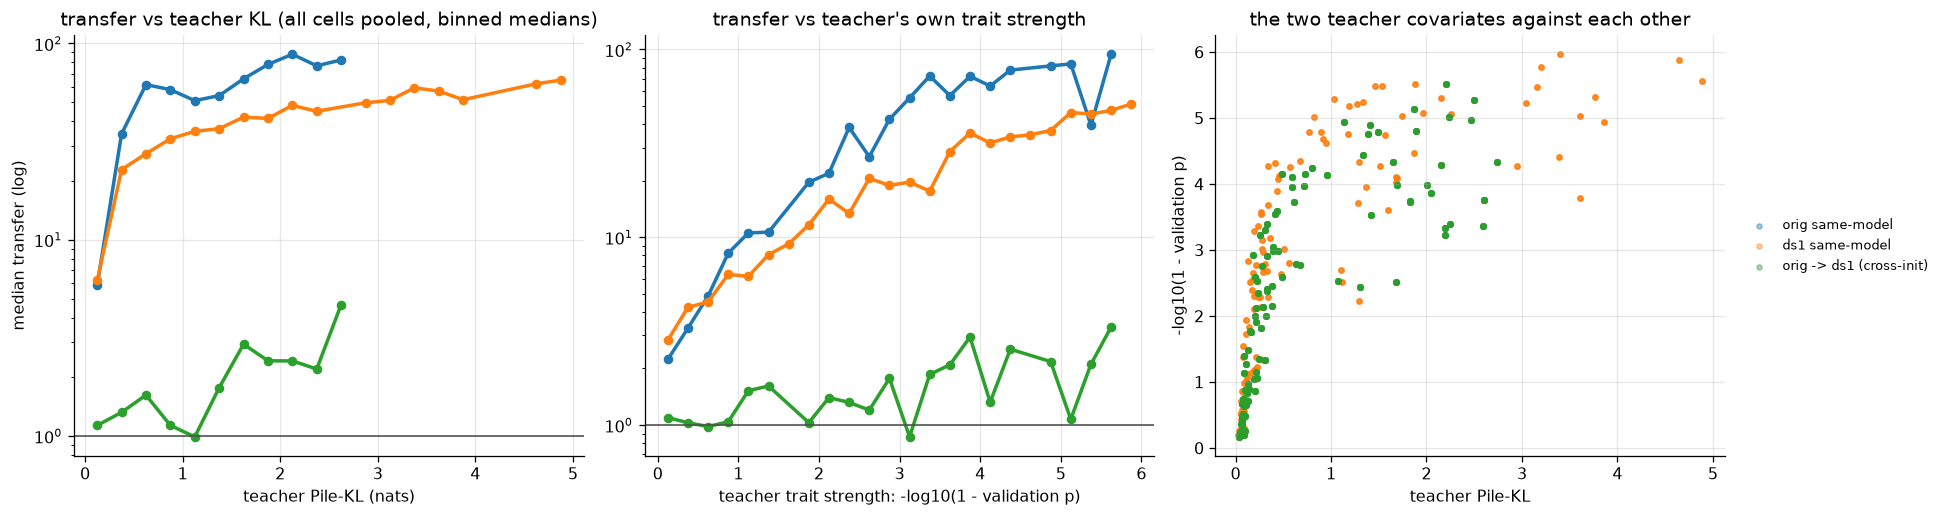

orig same-model: n=408 | KL-only (cell FE): b=+1.659 c=-0.507 (p=3.32e-15), vertex KL=1.64, R2=0.631 | + teacher val-p + log K_T: KL p=0.913, KL^2 p=0.843, val-p coef=+0.335 (p=5.81e-27), logK coef=+0.264 (p=7.81e-05), R2=0.780
ds1 same-model: n=472 | KL-only (cell FE): b=+0.693 c=-0.119 (p=3.38e-14), vertex KL=2.91, R2=0.719 | + teacher val-p + log K_T: KL p=0.95, KL^2 p=0.929, val-p coef=+0.211 (p=3.38e-77), logK coef=+0.198 (p=4.25e-10), R2=0.896
orig -> ds1 (cross-init): n=1233 | KL-only (cell FE): b=-0.060 c=+0.078 (p=0.196), vertex KL=0.39, R2=0.067 | + teacher val-p + log K_T: KL p=0.184, KL^2 p=0.086, val-p coef=+0.057 (p=0.105), logK coef=+0.014 (p=0.842), R2=0.075


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
colors = aplots.palette(list(ARMS))
for arm in ARMS:
    s = runs[runs.arm == arm]
    m, n = binned(s)
    axes[0].plot(m.index, m.values, "-o", color=colors[arm], lw=2.2, ms=5, label=f"{arm} (n={len(s)})")
    mv, _ = binned(s.assign(tv=-np.log10(1 - s.teacher_val_p.clip(upper=1 - 1e-6))), x="tv", w=0.25)
    axes[1].plot(mv.index, mv.values, "-o", color=colors[arm], lw=2.2, ms=5, label=arm)
    axes[2].scatter(s.teacher_kl, -np.log10(1 - s.teacher_val_p.clip(upper=1 - 1e-6)), s=10, alpha=0.4, color=colors[arm], label=arm)
for ax in axes[:2]:
    ax.axhline(1, color="0.3", lw=1); ax.set_yscale("log")
axes[0].set(xlabel="teacher Pile-KL (nats)", ylabel="median transfer (log)", title="transfer vs teacher KL (all cells pooled, binned medians)")
axes[1].set(xlabel="teacher trait strength: -log10(1 - validation p)", title="transfer vs teacher's own trait strength")
axes[2].set(xlabel="teacher Pile-KL", ylabel="-log10(1 - validation p)", title="the two teacher covariates against each other")
aplots.right_legend(axes[2], fontsize=8)
plt.tight_layout(); plt.show()

for arm in ARMS:
    s = runs[runs.arm == arm].copy()
    s["kl2"] = s.teacher_kl ** 2; s["tv"] = -np.log10(1 - s.teacher_val_p.clip(upper=1 - 1e-6)); s["logK"] = np.log10(s.teacher_K)
    f1 = smf.ols("log_transfer ~ C(student_tag) + teacher_kl + kl2", s).fit(cov_type="cluster", cov_kwds={"groups": s.teacher})
    f2 = smf.ols("log_transfer ~ C(student_tag) + teacher_kl + kl2 + tv + logK", s).fit(cov_type="cluster", cov_kwds={"groups": s.teacher})
    c, b = f1.params["kl2"], f1.params["teacher_kl"]
    print(f"{arm}: n={len(s)} | KL-only (cell FE): b={b:+.3f} c={c:+.3f} (p={f1.pvalues['kl2']:.3g}), vertex KL={-b/(2*c) if c else np.nan:.2f}, R2={f1.rsquared:.3f}"
          f" | + teacher val-p + log K_T: KL p={f2.pvalues['teacher_kl']:.3g}, KL^2 p={f2.pvalues['kl2']:.3g}, val-p coef={f2.params['tv']:+.3f} (p={f2.pvalues['tv']:.3g}), logK coef={f2.params['logK']:+.3f} (p={f2.pvalues['logK']:.3g}), R2={f2.rsquared:.3f}")

### 4b. Does KL add ordering where validation-p is saturated?

Angela's objection: "higher validation-score teachers are better" was already known, but
validation p saturates at ~1 almost immediately, so it cannot *order* the good teachers. Does
teacher KL order them? Restrict to teachers whose own validation p(dog) ≥ a threshold (0.9, 0.99,
0.999) and, within that subset, report Spearman(KL, transfer) and Spearman(val-p, transfer) per
arm (cell fixed: computed per cell, then the median over cells), plus the spread of transfer the
subset still has. If KL keeps a large ρ where val-p's ρ collapses, KL is the usable ordering
variable among saturated teachers. Row unit: one run; ρ per cell, median across the arm's cells.

teachers  rho_KL (median over cells)  rho_valp (median over cells)    val_p range      KL range transfer p10/p90
arm                      val_p >=                                                                                                                  
orig same-model          0.000          102                       0.891                         0.895  (0.3242, 1.0)  (0.03, 2.74)      (3.0, 86.2)
                         0.900           74                       0.776                         0.778  (0.9112, 1.0)  (0.09, 2.74)     (12.7, 90.7)
                         0.990           60                       0.652                         0.649  (0.9901, 1.0)  (0.18, 2.74)     (22.2, 92.0)
                         0.999           39                       0.441                         0.297  (0.9991, 1.0)  (0.25, 2.74)     (32.7, 95.3)
ds1 same-model           0.000          118                       0.948                         0.927  (0.3285, 1.0)  (0.03, 4.88)      (4.0, 52.0)
                         0.900           92                       0.912                         0.860  (0.9051, 1.0)  (0.08, 4.88)      (7.4, 55.4)
                         0.990           77                       0.889                         0.774  (0.9922, 1.0)  (0.13, 4.88)     (11.7, 57.4)
                         0.999           56                       0.846                         0.635   (0.999, 1.0)  (0.19, 4.88)     (16.2, 60.2)
orig -> ds1 (cross-init) 0.000          102                       0.191                         0.182  (0.3242, 1.0)  (0.03, 2.74)       (0.4, 4.6)
                         0.900           74                       0.145                         0.105  (0.9112, 1.0)  (0.09, 2.74)       (0.4, 5.3)
                         0.990           60                       0.209                         0.145  (0.9901, 1.0)  (0.18, 2.74)       (0.4, 5.7)
                         0.999           39                       0.274                         0.118  (0.9991, 1.0)  (0.25, 2.74)       (0.4, 7.0)

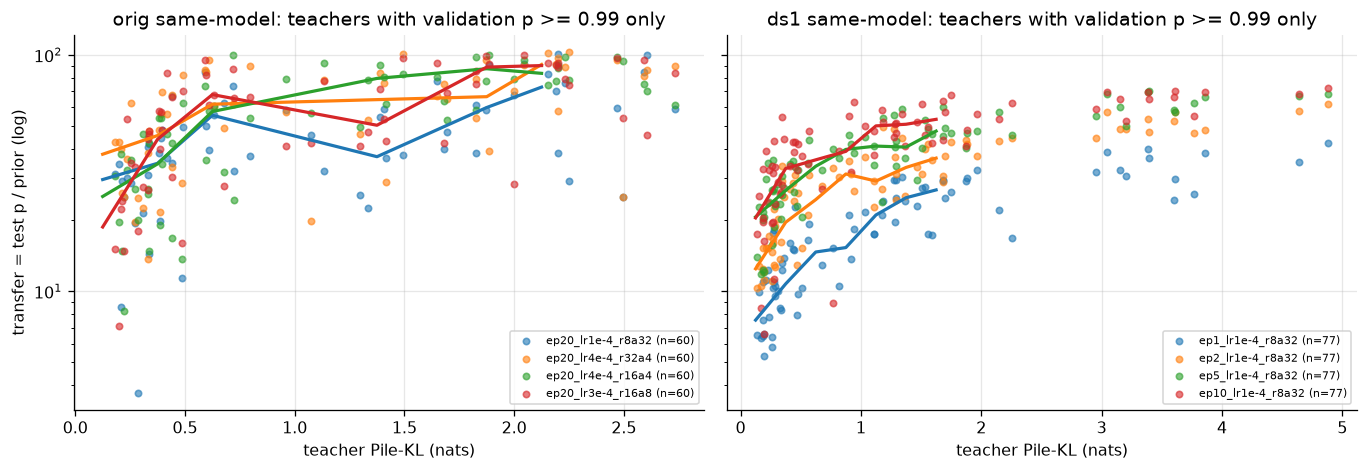

In [6]:
rows = []
for arm, (_, _, _, cells) in ARMS.items():
    for thr in (0.0, 0.9, 0.99, 0.999):
        sub = runs[(runs.arm == arm) & (runs.teacher_val_p >= thr)]
        rk, rv, ns = [], [], []
        for cell in cells:
            s = sub[sub.student_tag == cell]
            if s.teacher.nunique() < 8:
                continue
            rk.append(stats.spearmanr(s.teacher_kl, s.transfer).correlation)
            rv.append(stats.spearmanr(s.teacher_val_p, s.transfer).correlation)
            ns.append(s.teacher.nunique())
        if not ns:
            continue
        rows.append({"arm": arm, "val_p >=": thr, "teachers": int(np.median(ns)), "rho_KL (median over cells)": np.median(rk),
                     "rho_valp (median over cells)": np.median(rv),
                     "val_p range": (round(sub.teacher_val_p.min(), 4), round(sub.teacher_val_p.max(), 4)),
                     "KL range": (round(sub.teacher_kl.min(), 2), round(sub.teacher_kl.max(), 2)),
                     "transfer p10/p90": (round(sub.transfer.quantile(.1), 1), round(sub.transfer.quantile(.9), 1))})
sat = pd.DataFrame(rows).set_index(["arm", "val_p >="])
display(sat.round(3))

# the same thing visually for the same-model arms: among val-p >= 0.99 teachers, transfer vs KL
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, arm in zip(axes, ("orig same-model", "ds1 same-model")):
    sub = runs[(runs.arm == arm) & (runs.teacher_val_p >= 0.99)]
    for cell, c in zip(ARMS[arm][3], aplots.palette(ARMS[arm][3]).values()):
        s = sub[sub.student_tag == cell]
        ax.scatter(s.teacher_kl, s.transfer, s=16, alpha=0.6, color=c, label=f"{cell} (n={len(s)})")
        m, _ = binned(s)
        ax.plot(m.index, m.values, "-", color=c, lw=2)
    ax.set(xlabel="teacher Pile-KL (nats)", yscale="log", title=f"{arm}: teachers with validation p >= 0.99 only")
    ax.legend(fontsize=7)
axes[0].set_ylabel("transfer = test p / prior (log)")
plt.tight_layout(); plt.show()

## 5. Reading

Restated from the executed cells (see the tables above for the numbers behind each line).

In [7]:
for arm in ARMS:
    t = tests.loc[arm]
    print(f"{arm}:")
    for cell, r in t.iterrows():
        # a negative quadratic term with a vertex in the upper part of the range and no drop in the
        # top bins is SATURATION, not a hump: check the binned medians directly
        s_ = runs[(runs.arm == arm) & (runs.student_tag == cell)]
        m, _ = binned(s_)
        drop = (m.iloc[-2:].mean() / m.max()) if len(m) >= 3 else np.nan
        if r.interior_max and drop < 0.7:
            shape = "HUMP (interior max at KL~%.2f; top bins at %.0f%% of peak)" % (r.vertex_KL, 100 * drop)
        elif r.spearman > 0.5:
            shape = "monotone, SATURATING (top bins at %.0f%% of peak median)" % (100 * drop)
        else:
            shape = "monotone +" if r.spearman > 0.15 else "monotone -" if r.spearman < -0.15 else "flat/weak"
        print(f"   {cell:20s} n={int(r.n):4d} rho={r.spearman:+.2f} (p={r.spearman_p:.2g})  quad c={r.quad_c:+.2f} (p={r.quad_c_p:.2g})  -> {shape}; "
              f"top-decile teachers KL {r.top_decile_KL_med:.2f} vs rest {r.rest_KL_med:.2f}")
print("\nCaveats: orig-tree teachers are all on the distillable side of the ~2.7-nat gate (the far side of any sweet spot is censored);\n"
      "ds1-tree teachers reach KL ~4.9 and STILL saturate rather than decline. S4 shows KL has no effect once the teacher\x27s own\n"
      "trait strength (validation p) and recipe dose log K_T are in the model: KL is a proxy for how far the teacher was pushed.")

orig same-model:
   ep20_lr1e-4_r8a32    n= 102 rho=+0.86 (p=5.7e-31)  quad c=-0.44 (p=3.9e-10)  -> monotone, SATURATING (top bins at 91% of peak median); top-decile teachers KL 2.10 vs rest 0.26
   ep20_lr4e-4_r32a4    n= 102 rho=+0.88 (p=5.9e-35)  quad c=-0.51 (p=1.4e-10)  -> monotone, SATURATING (top bins at 87% of peak median); top-decile teachers KL 2.17 vs rest 0.26
   ep20_lr4e-4_r16a4    n= 102 rho=+0.91 (p=1.8e-40)  quad c=-0.54 (p=1.5e-18)  -> monotone, SATURATING (top bins at 98% of peak median); top-decile teachers KL 1.97 vs rest 0.26
   ep20_lr3e-4_r16a8    n= 102 rho=+0.90 (p=2e-37)  quad c=-0.54 (p=1.8e-13)  -> monotone, SATURATING (top bins at 99% of peak median); top-decile teachers KL 1.97 vs rest 0.26
ds1 same-model:
   ep1_lr1e-4_r8a32     n= 118 rho=+0.95 (p=3.1e-60)  quad c=-0.11 (p=1.8e-13)  -> monotone, SATURATING (top bins at 96% of peak median); top-decile teachers KL 3.20 vs rest 0.27
   ep2_lr1e-4_r8a32     n= 118 rho=+0.96 (p=6.9e-64)  quad c=-0.12 (p=1.7e